# Atelier 3 : Apprentissage supervisé
## Régression logistique (classification des fleurs d'Iris)

**Objectif :** classer les fleurs d'Iris en deux classes à partir de deux variables (*Sepal length* et *Sepal width*).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn import datasets
from sklearn.linear_model import LogisticRegression

# Chargement de la base de données iris
iris = datasets.load_iris()

# On garde les deux premières variables : Sepal length et Sepal width
X = iris.data[:, :2]
# Re-étiquetage : classe 0 (setosa) -> 0 ; classes 1 et 2 -> 1 (problème binaire)
y = (iris.target != 0) * 1

### Question 7 : Visualisation des données

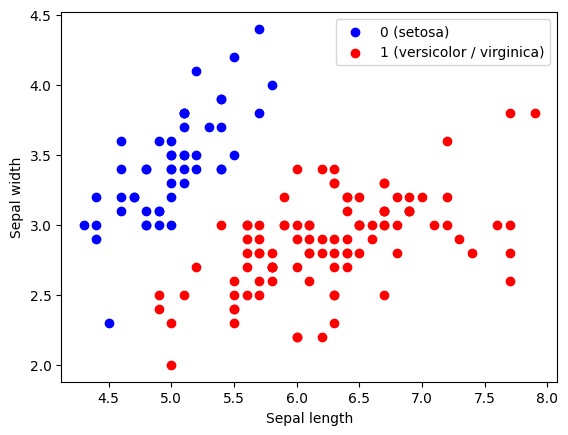

In [2]:
plt.scatter(X[y == 0][:, 0], X[y == 0][:, 1], c='b', label='0 (setosa)')
plt.scatter(X[y == 1][:, 0], X[y == 1][:, 1], c='r', label='1 (versicolor / virginica)')
plt.xlabel('Sepal length')
plt.ylabel('Sepal width')
plt.legend()
plt.show()

**Interprétation :**

- Le jeu contient 150 fleurs : 50 de classe 0 (setosa) et 100 de classe 1 (versicolor et virginica fusionnées). Les classes sont donc déséquilibrées (1/3 contre 2/3).
- Les deux classes forment **deux nuages distincts** : la classe 0 se place en haut à gauche (sépales courts, entre 4,3 et 5,8 cm, et plutôt larges), la classe 1 en bas et à droite (sépales plus longs, jusqu'à 7,9 cm, et plus étroits).
- Les deux classes semblent **séparables par une droite**, ce qui justifie l'usage d'un modèle linéaire comme la régression logistique.
- Une seule variable ne suffit pas : les longueurs de sépale se chevauchent entre les deux classes (autour de 5 cm), ainsi que les largeurs (entre 2,3 et 3,8 cm environ). C'est la combinaison des deux variables qui permet de séparer les classes.
- Un point de la classe 0 (environ 4,5 ; 2,3) est proche de la zone de la classe 1 : c'est le point le plus proche de la frontière.
- La classe 1 est plus étalée car elle regroupe deux espèces différentes.

### Entraînement du modèle

In [3]:
## TRAIN
model = LogisticRegression(C=1e20)
model.fit(X, y)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1e+20
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`m

### Question 8 : Prédiction sur de nouvelles fleurs

[5.5, 2.5] -> classe 1
[7, 3] -> classe 1
[3, 2] -> classe 0
[5, 3] -> classe 0


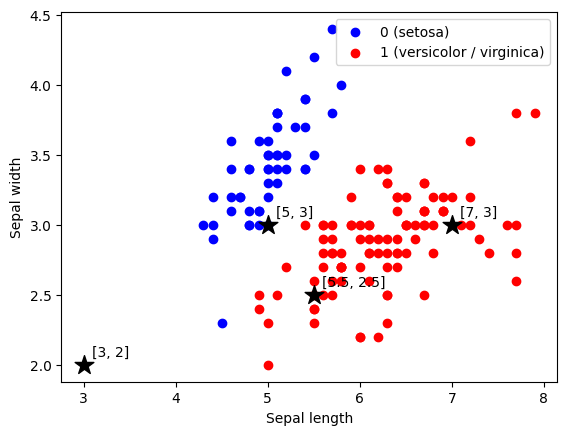

In [4]:
points = [[5.5, 2.5], [7, 3], [3, 2], [5, 3]]

for p in points:
    print(p, '-> classe', model.predict([p])[0])

# Vérification sur le scatter plot : les nouveaux points (étoiles noires)
plt.scatter(X[y == 0][:, 0], X[y == 0][:, 1], c='b', label='0 (setosa)')
plt.scatter(X[y == 1][:, 0], X[y == 1][:, 1], c='r', label='1 (versicolor / virginica)')
for p in points:
    plt.scatter(p[0], p[1], c='k', marker='*', s=200)
    plt.annotate(str(p), (p[0], p[1]), textcoords='offset points', xytext=(6, 6))
plt.xlabel('Sepal length')
plt.ylabel('Sepal width')
plt.legend()
plt.show()

**Interprétation :**

| Point [longueur, largeur] | Classe prédite | Vérification sur le scatter plot |
|---|---|---|
| [5.5, 2.5] | 1 | Zone rouge : sous le nuage bleu, parmi de nombreux points de la classe 1. |
| [7, 3] | 1 | Zone rouge : sépales longs, typiques de la classe 1. |
| [3, 2] | 0 | Hors de la zone des données (aucune fleur n'a une longueur inférieure à 4,3 cm). Le modèle linéaire prolonge sa frontière et classe ce point du côté de la classe 0, mais cette prédiction est une **extrapolation peu fiable**. |
| [5, 3] | 0 | En bordure droite du nuage bleu, près de la frontière : des fleurs de la classe 0 ont des valeurs proches, mais quelques points rouges sont aussi à proximité. C'est le cas le moins tranché des quatre. |

Les prédictions sont cohérentes avec la position des points sur le scatter plot, sauf pour [3, 2], qui sort du domaine d'apprentissage.